In [6]:
#import relevant libraries: pip install re, pip install natsort, pip install plotly==5.10.0
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import dabest
from datetime import datetime
date = datetime.today().strftime('%Y%m%d')

#NOTE: SUPPRESSES WARNINGS!

import warnings

warnings.simplefilter(action="ignore", category=RuntimeWarning)
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter("ignore", UserWarning)

In [7]:

openPath = "C:\\Users\\user\\NUS Dropbox\\acclab\\Nicole M Lee\\eOPN3 manuscript\\Data\\Fecundity\\"

files = os.listdir(openPath)
filename = openPath + "Toxicity_raw data.csv"

dfe=pd.read_csv(filename)

In [8]:
df = pd.concat([dfe['Genotype'], dfe['Hatched'], dfe['Eclosed']], axis = 1)

if df['Genotype'].str.contains(" ACR").any():
   df['Genotype'] = df['Genotype'].str.replace(" ACR", " GtACR1")
   
if df['Genotype'].str.contains("[ATR]").any():
   df['Genotype'] = df['Genotype'].str.replace(" [ATR]", "*")

df['number'] = pd.factorize(df.Genotype)[0].tolist()

repeats = int(df[df.number == 1].number.value_counts().values[0])

In [9]:
dftotal = pd.DataFrame()
dfnumbers = pd.DataFrame()
for n in df['Genotype'].unique():
    df1 = pd.DataFrame()
    df2 = pd.DataFrame()
    embryos = int(df[df['Genotype'] == n]['Hatched'].sum())
    eclosed = int(df[df['Genotype'] == n]['Eclosed'].sum())
    
    #total embryos
    df1[n+" (H)"] = [1]*embryos
    df2[n+"_embryos"] = [embryos]
    
    #total pupate
    failpupate =embryos-eclosed                        
    df1[n + " (E)"] = [0]*failpupate + [1]*eclosed 
    df2[n + "_eclose"] = [eclosed]
    
    df1['ID'] = range(1, len(df1)+1)
    # dftotal = pd.concat([dftotal,df1], axis =1).reset_index(drop = True)
    dfnumbers = pd.concat([dfnumbers,df2], axis =1).reset_index(drop = True)
    
    dfmelted = pd.melt(df1, id_vars = ["ID"], value_vars=df1.columns[:-1])

    dftotal = pd.concat([dfmelted, dftotal], axis = 0).reset_index(drop = True)
    

dftotal['lethality'] = dftotal['value'] = 1 - dftotal['value']

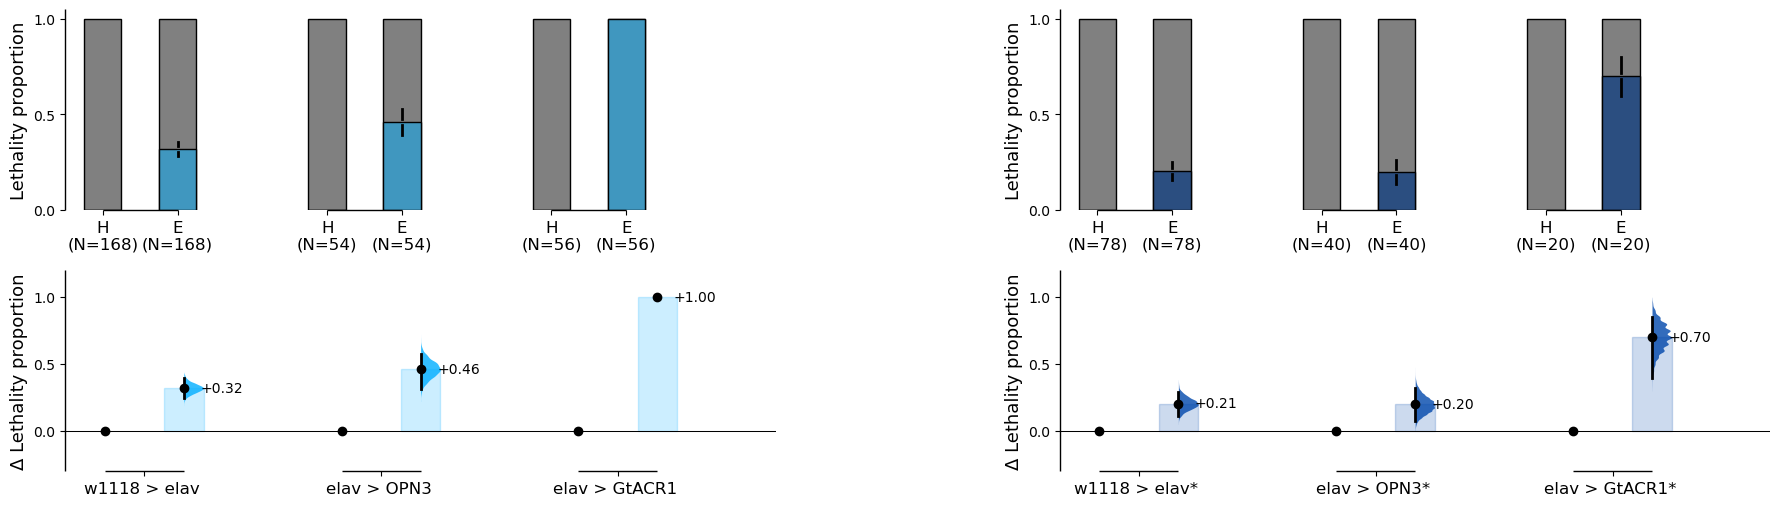

In [10]:
from matplotlib.collections import PolyCollection

multi_groups_baseline_1 = dabest.load(dftotal, idx=(("w1118 x elav (H)", 'w1118 x elav (E)' )
                                                    ,("elav x OPN3 (H)", 'elav x OPN3 (E)')
                                                    ,("elav x GtACR1 (H)", 'elav x GtACR1 (E)')), x = "variable", y = "lethality",
                                          proportional=True)

multi_groups_baseline_2 = dabest.load(dftotal, idx=(("w1118 x elav* (H)", 'w1118 x elav* (E)' )
                                                    ,("elav x OPN3* (H)", 'elav x OPN3* (E)')
                                                    ,("elav x GtACR1* (H)", 'elav x GtACR1* (E)')), x = "variable", y = "lethality",
                                          proportional=True)

fig, axes = plt.subplots(1, 2, figsize=(22, 6), gridspec_kw={'wspace': 0.4})

common_style = {'fontsize_rawxlabel': 9, 'fontsize_rawylabel': 13, 'fontsize_contrastxlabel': 9,
                'fontsize_contrastylabel': 13, 'fontsize_delta2label': 12, 'contrast_marker_size': 6}

group_gap = 1

for ax_raw, dabest_obj, color in [(axes[0], multi_groups_baseline_1, "#00AEFF"),
                                  (axes[1], multi_groups_baseline_2, "#0047AB")]:
    dabest_obj.mean_diff.plot(custom_palette={0: "#808080", 1: color},
        contrast_ylim=(-0.3, 1.2), bar_width=0.5, ax=ax_raw, **common_style)
    contrast_ax = ax_raw.contrast_axes

    for p in contrast_ax.patches:
        p.set_facecolor(color)
        p.set_edgecolor(color)
    for col in contrast_ax.collections:
        if isinstance(col, PolyCollection):
            col.set_facecolor(color)
            col.set_edgecolor(color)

    ax_raw.set_ylabel('Lethality proportion')
    contrast_ax.set_ylabel('Δ Lethality proportion')

    results = dabest_obj.mean_diff.results
    n = results['control_N']
    gen = [g.split("(")[0].replace("x", ">") for g in results['control']]

    contrast_ax.spines['bottom'].set_visible(False)
    contrast_ax.set_xticks([0.5, 2.5, 4.5])
    ax_raw.set_xticklabels([f"{s}\n(N={n[i]})" for i in range(3) for s in "HE"], fontsize=12)
    contrast_ax.set_xticklabels(gen, fontsize=12)

    ax_raw.set_yticks([0.0, 0.5, 1.0])
    contrast_ax.set_yticks([0.0, 0.5, 1.0])

    for a in (ax_raw, contrast_ax):
        for l in a.lines:
            if l.get_transform() == a.transData:
                x = np.asarray(l.get_xdata(), float)
                l.set_xdata(x + np.floor((x.mean() + 0.5) / 2) * group_gap)
        for p in a.patches:
            p.set_x(p.get_x() + np.floor((p.get_x() + p.get_width() / 2 + 0.5) / 2) * group_gap)
        for col in a.collections:
            for path in col.get_paths():
                path.vertices[:, 0] += np.floor((path.vertices[:, 0].mean() + 0.5) / 2) * group_gap
        for t in a.texts:
            x, y = t.get_position()
            t.set_position((x + np.floor((x + 0.5) / 2) * group_gap, y))
        ticks, labels = a.get_xticks(), [t.get_text() for t in a.get_xticklabels()]
        a.set_xticks(ticks + np.floor((ticks + 0.5) / 2) * group_gap, labels)
        a.set_xlim(a.get_xlim()[0], a.get_xlim()[1] + 2 * group_gap)

mpl.rcParams['svg.fonttype'] = 'none'
fig.savefig(openPath + date + "_Fecundity_EMPE_lethality_ACR.svg", bbox_inches = 'tight')
plt.show()